# LAB 01 — Khám phá và chuẩn bị dữ liệu Student Performance Factors

**DNU Learning Analytics Lab**

- **Họ tên:** Lê Trung Kiên
- **MSSV:** 1771020404
- **Lớp:** CNTT18-02

> **Câu hỏi trung tâm:** Dataset này có đủ hiểu, đủ sạch và đủ phù hợp để bắt đầu modeling chưa?
> - **Đủ hiểu:** Đã xác định mỗi dòng đại diện cho một người học, dataset gồm 6.607 samples và 20 variables, trong đó `Exam_Score` là target của bài toán hồi quy. EDA cho thấy điểm tập trung quanh 67 và có liên hệ dương với chuyên cần, số giờ học; tuy nhiên vẫn cần làm rõ quy tắc chấm điểm và bối cảnh thu thập dữ liệu.
> - **Đủ sạch:** Đã xử lý missing ở ba cột bằng mode trên `df_clean`, nhưng điểm 101 cần được đối chiếu với nguồn và thang điểm trước khi quyết định xử lý. Không nên tự động xóa hoặc cap một giá trị chỉ vì nó là ngoại lệ.
> - **Đủ phù hợp:** Dữ liệu có target và các features phù hợp để thử nghiệm dự đoán điểm thi, nhưng cần mã hóa biến phân loại, kiểm tra thông tin có sẵn trước kỳ thi và chia train/validation/test. Các bước điền missing, mã hóa và chuẩn hóa nếu cần phải được fit chỉ trên train để tránh rò rỉ dữ liệu.
> - **Kết luận:** Dataset đã sẵn sàng cho EDA, nhưng cần hoàn tất xác minh dữ liệu và preprocessing trước khi huấn luyện mô hình baseline. Khả năng dự đoán và khái quát hóa phải được đánh giá trên dữ liệu chưa dùng để huấn luyện, không thể kết luận chỉ từ các biểu đồ tương quan.



## Environment checkpoint

Chạy cell dưới đây. Nếu không có lỗi import, môi trường đã sẵn sàng cho bài lab.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Environment ready!")
print("pandas:", pd.__version__)


Environment ready!
pandas: 3.0.6


# Mission 1 — Understand the dataset

## Nhiệm vụ

1. Đọc file `data/StudentPerformanceFactors.csv`.
2. Quan sát các dòng đầu tiên.
3. Kiểm tra kích thước dataset.
4. Kiểm tra kiểu dữ liệu và non-null count.
5. Trả lời bằng Markdown:
   - Một row đại diện cho đối tượng nào?
   - Dataset có bao nhiêu samples và variables?
   - Target gốc là cột nào?
   - Nếu dự đoán trực tiếp target này, đây là regression hay classification?


In [4]:
# Đọc dữ liệu bằng đường dẫn tương đối
df = pd.read_csv("data/StudentPerformanceFactors.csv")

# Khám phá sơ bộ
display(df.head())
print("Shape:", df.shape)
df.info()


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


Shape: (6607, 20)
<class 'pandas.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Hours_Studied               6607 non-null   int64
 1   Attendance                  6607 non-null   int64
 2   Parental_Involvement        6607 non-null   str  
 3   Access_to_Resources         6607 non-null   str  
 4   Extracurricular_Activities  6607 non-null   str  
 5   Sleep_Hours                 6607 non-null   int64
 6   Previous_Scores             6607 non-null   int64
 7   Motivation_Level            6607 non-null   str  
 8   Internet_Access             6607 non-null   str  
 9   Tutoring_Sessions           6607 non-null   int64
 10  Family_Income               6607 non-null   str  
 11  Teacher_Quality             6529 non-null   str  
 12  School_Type                 6607 non-null   str  
 13  Peer_Influence              6607 non-null   str  
 14  P

### Kết luận Mission 1

- Một row đại diện cho: **một sinh viên**
- Số samples: **6607**
- Số variables: **20**
- Target gốc: **Exam_Score**
- Dạng bài toán nếu dự đoán trực tiếp target: **Regression (hồi quy)**

**Giải thích ngắn:**  
Mỗi dòng trong dataset chứa thông tin về một sinh viên và các yếu tố liên quan đến kết quả học tập. Dataset có 6607 samples và 20 variables. Target là `Exam_Score`, đây là dữ liệu dạng số nên nếu dự đoán trực tiếp điểm thi thì đây là bài toán hồi quy.

# Mission 2 — Build a data dictionary

Pandas dtype cho biết cách máy đang lưu dữ liệu, nhưng không phải lúc nào cũng phản ánh đầy đủ **ý nghĩa dữ liệu**.

Hãy phân loại các cột thành:

- numerical;
- categorical;
- ordinal categorical;
- target.

Tạo một bảng Data Dictionary có tối thiểu các cột:

| Variable | Ý nghĩa | Pandas dtype | Semantic type | Vai trò dự kiến |
|---|---|---|---|---|


In [5]:
# Gợi ý: xác định nhanh nhóm cột theo dtype
numeric_cols = df.select_dtypes(include="number").columns.tolist()
categorical_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numeric columns:")
print(numeric_cols)

print("\nCategorical-like columns:")
print(categorical_cols)


The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.
Numeric columns:
['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity', 'Exam_Score']

Categorical-like columns:
['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']


/var/folders/b5/g2rjryx52fq91pbnc54ljk2c0000gn/T/ipykernel_71073/2809185964.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()


### Data Dictionary

Hoàn thiện bảng cho **tất cả các biến** trong dataset.

| Variable | Ý nghĩa | Pandas dtype | Semantic type | Vai trò dự kiến |
|---|---|---|---|---|
| Hours_Studied | Số giờ học | int64 | Numerical | Feature |
| Attendance | Tỷ lệ chuyên cần | int64 | Numerical | Feature |
| Parental_Involvement | Mức độ tham gia của phụ huynh | object | Ordinal categorical | Feature |
| Access_to_Resources | Mức độ tiếp cận tài nguyên học tập | object | Ordinal categorical | Feature |
| Extracurricular_Activities | Tham gia hoạt động ngoại khóa | object | Categorical | Feature |
| Sleep_Hours | Số giờ ngủ | int64 | Numerical | Feature |
| Previous_Scores | Điểm số trước đó | int64 | Numerical | Feature |
| Motivation_Level | Mức độ động lực học tập | object | Ordinal categorical | Feature |
| Internet_Access | Có quyền truy cập Internet hay không | object | Categorical | Feature |
| Tutoring_Sessions | Số buổi học phụ đạo | int64 | Numerical | Feature |
| Family_Income | Mức thu nhập gia đình | object | Ordinal categorical | Feature |
| Teacher_Quality | Chất lượng giáo viên | object | Ordinal categorical | Feature |
| School_Type | Loại trường | object | Categorical | Feature |
| Peer_Influence | Mức độ ảnh hưởng của bạn bè | object | Ordinal categorical | Feature |
| Physical_Activity | Mức độ hoạt động thể chất | int64 | Numerical | Feature |
| Learning_Disabilities | Có khó khăn trong học tập hay không | object | Categorical | Feature |
| Parental_Education_Level | Trình độ học vấn của phụ huynh | object | Ordinal categorical | Feature |
| Distance_from_Home | Khoảng cách từ nhà đến trường | object | Ordinal categorical | Feature |
| Gender | Giới tính | object | Categorical | Feature |
| Exam_Score | Điểm thi | int64 | Numerical | Target |

### Câu hỏi tư duy

1. Có cột nào Pandas đọc là `object` nhưng về ý nghĩa lại có thứ tự không?
2. Tại sao phân biệt này quan trọng khi chuẩn bị dữ liệu cho machine learning?

### Trả lời câu hỏi tư duy

**1. Có cột nào Pandas đọc là object nhưng về ý nghĩa lại có thứ tự không?**

Có. Ví dụ `Parental_Involvement`, `Access_to_Resources`, `Motivation_Level`, `Family_Income`, `Teacher_Quality`, `Parental_Education_Level` và `Distance_from_Home`. Các cột này được Pandas lưu dưới dạng object nhưng các giá trị có thứ tự về mặt ý nghĩa, ví dụ Low < Medium < High.

**2. Tại sao phân biệt này quan trọng khi chuẩn bị dữ liệu cho machine learning?**

Vì cách mã hóa dữ liệu phụ thuộc vào ý nghĩa của biến. Với biến categorical thông thường, các nhóm không có thứ tự. Trong khi đó ordinal categorical có thứ tự tự nhiên nên cần giữ lại thông tin về thứ tự khi mã hóa. Phân loại sai có thể làm mất thông tin hoặc khiến mô hình hiểu sai dữ liệu.


# Mission 3 — Data Quality Audit

## Câu hỏi

Dataset có các vấn đề nào sau đây không?

- missing values;
- duplicated rows;
- kiểu dữ liệu bất hợp lý;
- category không nhất quán;
- giá trị số bất thường;
- target không hợp lệ.

Hãy **kiểm tra trước khi xử lý**.


In [6]:
# 1. Missing values
missing = df.isna().sum().sort_values(ascending=False)
display(missing[missing > 0])

# 2. Duplicates
print("Duplicated rows:", df.duplicated().sum())

# 3. Thống kê mô tả
display(df.describe(include="all").T)


Parental_Education_Level    90
Teacher_Quality             78
Distance_from_Home          67
dtype: int64

Duplicated rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Hours_Studied,6607.0,NaN,NaN,NaN,19.975329,5.990594,1.0,16.0,20.0,24.0,44.0
Attendance,6607.0,NaN,NaN,NaN,79.977448,11.547475,60.0,70.0,80.0,90.0,100.0
Parental_Involvement,6607,3,Medium,3362,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Access_to_Resources,6607,3,Medium,3319,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Extracurricular_Activities,6607,2,Yes,3938,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sleep_Hours,6607.0,NaN,NaN,NaN,7.02906,1.46812,4.0,6.0,7.0,8.0,10.0
Previous_Scores,6607.0,NaN,NaN,NaN,75.070531,14.399784,50.0,63.0,75.0,88.0,100.0
Motivation_Level,6607,3,Medium,3351,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Internet_Access,6607,2,Yes,6108,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tutoring_Sessions,6607.0,NaN,NaN,NaN,1.493719,1.23057,0.0,1.0,1.0,2.0,8.0


In [7]:
# 4. Quan sát các giá trị của biến categorical
for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))



--- Parental_Involvement ---
Parental_Involvement
Medium    3362
High      1908
Low       1337
Name: count, dtype: int64

--- Access_to_Resources ---
Access_to_Resources
Medium    3319
High      1975
Low       1313
Name: count, dtype: int64

--- Extracurricular_Activities ---
Extracurricular_Activities
Yes    3938
No     2669
Name: count, dtype: int64

--- Motivation_Level ---
Motivation_Level
Medium    3351
Low       1937
High      1319
Name: count, dtype: int64

--- Internet_Access ---
Internet_Access
Yes    6108
No      499
Name: count, dtype: int64

--- Family_Income ---
Family_Income
Low       2672
Medium    2666
High      1269
Name: count, dtype: int64

--- Teacher_Quality ---
Teacher_Quality
Medium    3925
High      1947
Low        657
NaN         78
Name: count, dtype: int64

--- School_Type ---
School_Type
Public     4598
Private    2009
Name: count, dtype: int64

--- Peer_Influence ---
Peer_Influence
Positive    2638
Neutral     2592
Negative    1377
Name: count, dtype: int6

### Data Quality Report — trước khi cleaning

| Vấn đề | Có/Không | Bằng chứng | Mức độ cần xử lý |
|---|---|---|---|
| Missing values | Có | Parental_Education_Level: 90, Teacher_Quality: 78, Distance_from_Home: 67 | Cần xử lý |
| Duplicates | Không | Duplicated rows = 0 | Không cần xử lý |
| Kiểu dữ liệu bất hợp lý | Không đáng kể | Các cột numerical được đọc dạng số; categorical được lưu dạng chuỗi | Không cần xử lý ngay |
| Category không nhất quán | Không | Các category quan sát được đều nhất quán, ví dụ Low/Medium/High, Yes/No | Không cần xử lý |
| Giá trị số đáng ngờ | Có | Exam_Score có max = 101 | Cần kiểm tra thêm |

**Nhận xét:**

Dataset không có dòng dữ liệu trùng lặp và các giá trị categorical nhìn chung khá nhất quán. Tuy nhiên, có missing values ở 3 cột: `Parental_Education_Level` (90), `Teacher_Quality` (78) và `Distance_from_Home` (67). Các giá trị thiếu này cần được xem xét và xử lý trước khi modeling. Ngoài ra, `Exam_Score` có giá trị lớn nhất là 101, đây là giá trị đáng ngờ nếu điểm thi thông thường có giới hạn 100 và cần được kiểm tra thêm trước khi quyết định xử lý.


# Mission 4 — Investigate suspicious data

Không phải dữ liệu “lạ” nào cũng là dữ liệu “sai”.

## Nhiệm vụ

1. Kiểm tra min/max của `Exam_Score`.
2. Nếu có giá trị vượt ngoài khoảng mà bạn cho là hợp lý, tìm record đó.
3. Không xóa ngay.
4. Trả lời:
   - Đây có phải outlier không?
   - Có đủ bằng chứng để gọi đây là lỗi dữ liệu không?
   - Bạn sẽ giữ, xóa, cap hay kiểm tra nguồn trước? Vì sao?


In [10]:
# Điều tra Exam_Score
display(df["Exam_Score"].describe())

# Tìm các record có Exam_Score vượt quá 100
suspicious_scores = df[df["Exam_Score"] > 100]

display(suspicious_scores)

print("Số record có Exam_Score > 100:", len(suspicious_scores))

count    6607.000000
mean       67.235659
std         3.890456
min        55.000000
25%        65.000000
50%        67.000000
75%        69.000000
max       101.000000
Name: Exam_Score, dtype: float64

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
1525,27,98,Low,Medium,Yes,6,93,Low,No,5,High,High,Public,Positive,3,No,High School,Moderate,Female,101


Số record có Exam_Score > 100: 1


### Kết luận Mission 4

**Quan sát:** `Exam_Score` có giá trị nhỏ nhất là 55 và lớn nhất là 101. Có 1 record có điểm lớn hơn 100, tại index 1525.

**Quyết định đề xuất:** Kiểm tra nguồn dữ liệu trước, chưa xóa hoặc chỉnh sửa ngay.

**Lý do:** Giá trị 101 là một outlier và vượt mức 100 nếu giả định thang điểm tối đa là 100. Tuy nhiên, chỉ dựa vào giá trị này chưa đủ bằng chứng để kết luận đây là lỗi dữ liệu. Record này vẫn có các thông tin khác hợp lệ. Vì vậy nên kiểm tra nguồn hoặc quy tắc chấm điểm trước khi quyết định giữ, xóa hoặc cap giá trị.

> Nhớ: Outlier ≠ Error.


# Mission 5 — Handle missing values

## Nhiệm vụ

Với từng cột có missing values:

1. Xác định semantic type.
2. Đề xuất một chiến lược xử lý.
3. Giải thích vì sao.
4. Tạo `df_clean` từ `df.copy()` rồi thực hiện lựa chọn của bạn.

Các lựa chọn có thể cân nhắc:

- loại bỏ record;
- điền mode;
- tạo category `Unknown`;
- hoặc giữ missing để xử lý trong pipeline sau.

Không có một đáp án mặc định cho mọi cột.


In [11]:
df_clean = df.copy()

# Điền missing values bằng mode của từng cột
missing_cols = [
    "Parental_Education_Level",
    "Teacher_Quality",
    "Distance_from_Home"
]

for col in missing_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

print("Missing values after your processing:")
display(df_clean.isna().sum()[df_clean.isna().sum() > 0])


Missing values after your processing:


Series([], dtype: int64)

### Giải thích chiến lược xử lý missing

| Cột | Chiến lược | Lý do |
|---|---|---|
| Parental_Education_Level | Điền mode | Là biến ordinal categorical và chỉ thiếu 90 giá trị; dùng mode giúp giữ lại các record |
| Teacher_Quality | Điền mode | Là biến ordinal categorical và chỉ thiếu 78 giá trị; mode là cách đơn giản, phù hợp với bài lab |
| Distance_from_Home | Điền mode | Là biến ordinal categorical và chỉ thiếu 67 giá trị; dùng mode tránh phải xóa các record |

Cả ba cột có số lượng missing nhỏ so với tổng số 6607 samples. Vì vậy, tôi chọn điền giá trị phổ biến nhất (mode) thay vì xóa các record để tránh làm mất dữ liệu. Việc xử lý được thực hiện trên `df_clean` để giữ nguyên dataset gốc.


# Mission 6 — EDA driven by questions

Trong phần này, **biểu đồ là công cụ để trả lời câu hỏi**, không phải mục tiêu.

Mỗi biểu đồ phải đi kèm nhận xét ngắn.


## Question 1 — `Exam_Score` phân bố như thế nào?

Hãy dùng histogram.

Quan sát:

- điểm tập trung ở đâu?
- phân bố có lệch không?
- có giá trị bất thường không?


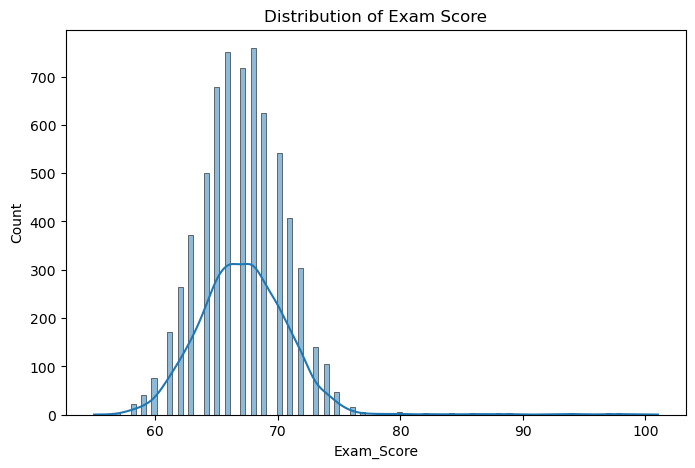

count    6607.000000
mean       67.235659
std         3.890456
min        55.000000
25%        65.000000
50%        67.000000
75%        69.000000
max       101.000000
Name: Exam_Score, dtype: float64

Skewness: 1.645
Scores outside [0, 100]: 1


In [12]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df_clean, x="Exam_Score", kde=True)
plt.title("Distribution of Exam Score")
plt.show()

display(df_clean["Exam_Score"].describe())
print("Skewness:", round(df_clean["Exam_Score"].skew(), 3))
print("Scores outside [0, 100]:", ((df_clean["Exam_Score"] < 0) | (df_clean["Exam_Score"] > 100)).sum())

**Nhận xét Q1:**
Điểm thi tập trung quanh 67 điểm, với 50% quan sát nằm trong khoảng 65–69 và điểm trung bình khoảng 67,24. Phân bố lệch phải, có đuôi kéo dài về phía điểm cao (skewness khoảng 1,645). Điểm dao động từ 55 đến 101; có một giá trị 101 vượt thang điểm 0–100 nếu đây là thang điểm được áp dụng. Cần kiểm tra nguồn và quy tắc chấm điểm trước khi kết luận giá trị này là lỗi hoặc xóa/cap nó.

## Question 2 — Học nhiều hơn có đồng nghĩa điểm cao hơn?

Vẽ `Hours_Studied` vs `Exam_Score`.


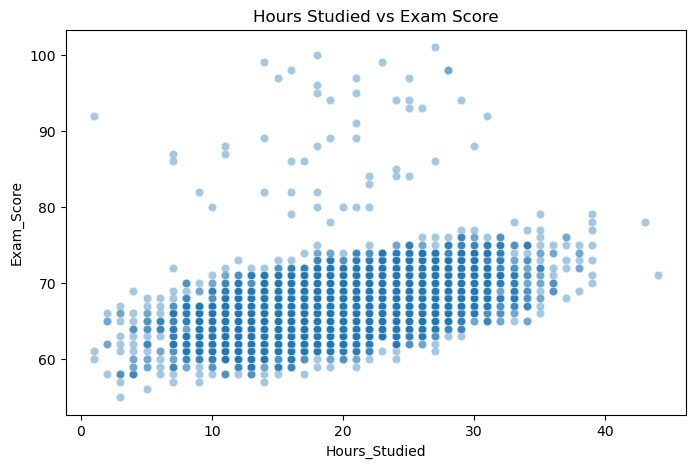

In [13]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_clean, x="Hours_Studied", y="Exam_Score", alpha=0.4)
plt.title("Hours Studied vs Exam Score")
plt.show()


**Nhận xét Q2:**
Biểu đồ cho thấy xu hướng dương: học sinh có Hours_Studied cao hơn thường có Exam_Score cao hơn, với tương quan Pearson khoảng 0,445 (xem bảng ở Q3). Tuy nhiên, điểm vẫn phân tán khá rộng ở cùng số giờ học, nên học nhiều hơn không bảo đảm mỗi học sinh sẽ đạt điểm cao hơn. Mối liên hệ này có thể chịu ảnh hưởng của chuyên cần, kiến thức nền và các yếu tố khác; không thể suy ra rằng chỉ tăng giờ học sẽ trực tiếp làm tăng điểm.

> Lưu ý: tương quan không đồng nghĩa nhân quả.

## Question 3 — `Attendance` hay `Hours_Studied` trông hữu ích hơn?

Vẽ `Attendance` vs `Exam_Score`, sau đó so sánh với biểu đồ trước.


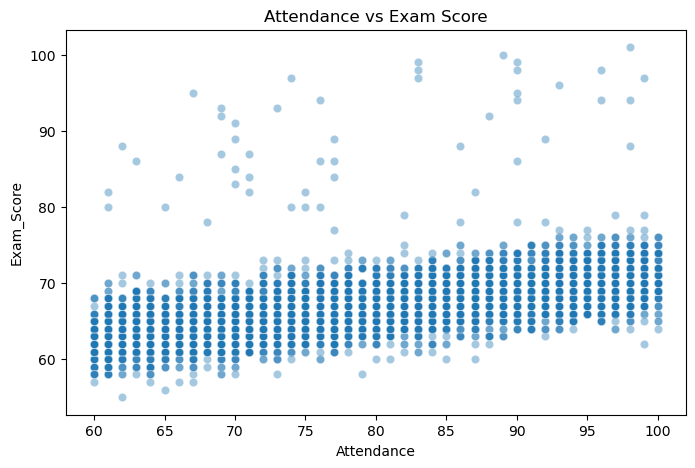

,Hours_Studied,Attendance,Previous_Scores,Exam_Score
Hours_Studied,1.000000,-0.009908,0.024846,0.445455
Attendance,-0.009908,1.000000,-0.020186,0.581072
Previous_Scores,0.024846,-0.020186,1.000000,0.175079
Exam_Score,0.445455,0.581072,0.175079,1.000000


In [14]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_clean, x="Attendance", y="Exam_Score", alpha=0.4)
plt.title("Attendance vs Exam Score")
plt.show()

corr_cols = ["Hours_Studied", "Attendance", "Previous_Scores", "Exam_Score"]
display(df_clean[corr_cols].corr())


**Nhận xét Q3:**
Attendance có mối liên hệ tuyến tính dương với Exam_Score rõ hơn Hours_Studied: hệ số tương quan Pearson lần lượt khoảng 0,581 và 0,445. Vì vậy, xét riêng từng biến trên dataset này, Attendance có vẻ hữu ích hơn để dự đoán điểm. Tuy nhiên, các điểm dữ liệu vẫn phân tán nên cả hai biến đều không giải thích đầy đủ kết quả thi. Nên cân nhắc kết hợp chúng và đánh giá trên tập kiểm tra; tương quan cao hơn không chứng minh quan hệ nhân quả.

## Question 4 — Các mức `Motivation_Level` có phân bố `Exam_Score` giống nhau không?

Chọn biểu đồ phù hợp cho biến categorical/ordinal.


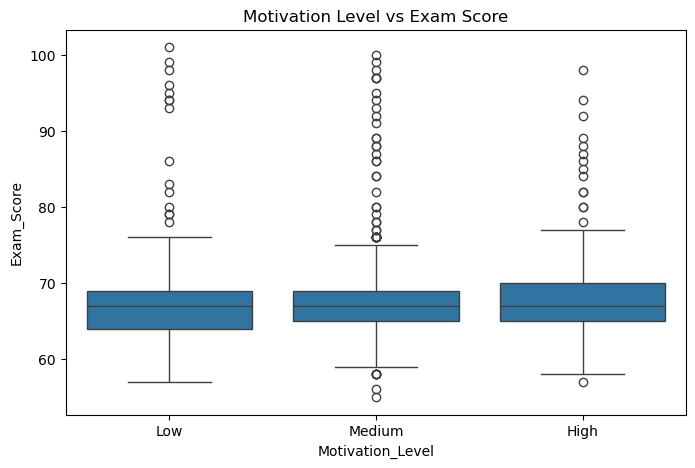

,count,mean,median,std
Motivation_Level,,,,
Low,1937,66.752194,67.0,3.958139
Medium,3351,67.330648,67.0,3.827303
High,1319,67.704321,67.0,3.876966


In [15]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean, x="Motivation_Level", y="Exam_Score", order=["Low", "Medium", "High"])
plt.title("Motivation Level vs Exam Score")
plt.show()

display(df_clean.groupby("Motivation_Level")["Exam_Score"]
        .agg(["count", "mean", "median", "std"])
        .reindex(["Low", "Medium", "High"]))

**Nhận xét Q4:**
Boxplot cho thấy phân bố điểm của ba nhóm Low, Medium và High chồng lấn nhiều, với trung vị đều bằng 67. Điểm trung bình tăng nhẹ theo mức động lực: khoảng 66,75 ở Low, 67,33 ở Medium và 67,70 ở High. Độ phân tán của các nhóm khá tương tự và đều có các điểm ngoại lệ, nên Motivation_Level riêng lẻ chưa phân biệt rõ học sinh điểm cao và thấp.

**Có thể kết luận quan hệ nhân quả không? Vì sao?**
Không, vì đây là dữ liệu quan sát và boxplot chỉ thể hiện sự khác biệt giữa các nhóm. Những yếu tố khác như thời gian học, chuyên cần hoặc điểm trước đó có thể liên quan đồng thời đến động lực và điểm thi; cần thiết kế nghiên cứu phù hợp và kiểm soát yếu tố gây nhiễu để đánh giá nhân quả.

# Final — Data Readiness Report

Báo cáo của **DNU Learning Analytics Lab**.

## 1. Bài toán

Chúng tôi muốn dự đoán **điểm thi của học sinh từ các đặc điểm học tập và điều kiện hỗ trợ có sẵn trước kỳ thi**, nhằm hỗ trợ nhận diện nhu cầu hỗ trợ học tập. Đây là bài toán học có giám sát dạng **hồi quy**, vì đầu ra là một giá trị điểm số.

## 2. Target

`Exam_Score` — điểm thi cần dự đoán; không đưa cột này vào tập features.

## 3. Features dự kiến

Ưu tiên `Hours_Studied`, `Attendance` và `Previous_Scores`; cân nhắc bổ sung `Motivation_Level`, `Teacher_Quality`, `Parental_Education_Level` và `Distance_from_Home`. Đây là các biến mô tả việc học, kết quả trước đó và điều kiện hỗ trợ học sinh. Chỉ sử dụng thông tin có sẵn tại thời điểm dự đoán, mã hóa phù hợp các biến phân loại và đánh giá giá trị của features bằng validation thay vì chỉ dựa vào tương quan.

## 4. Vấn đề dữ liệu đã phát hiện

- Dataset có 6.607 quan sát; `Parental_Education_Level` thiếu 90 giá trị, `Teacher_Quality` thiếu 78 và `Distance_from_Home` thiếu 67.
- `Exam_Score` nằm trong khoảng 55–101, có một giá trị 101 cần xác minh nếu thang điểm quy định là 0–100. Phân bố lệch phải và có các điểm cao khác biệt; ngoại lệ thống kê chưa đủ để kết luận là lỗi dữ liệu.
- Các features phân loại vẫn cần được chuyển thành dạng số phù hợp trước khi đưa vào phần lớn mô hình; các biến số có thang đo khác nhau.

## 5. Cách xử lý đã chọn

Đã tạo `df_clean = df.copy()` để giữ nguyên dữ liệu gốc, sau đó điền missing của ba cột trên bằng mode của từng cột. Cách này giữ lại các quan sát khi tỷ lệ thiếu ở mỗi cột nhỏ; kết quả kiểm tra trên `df_clean` không còn missing, nhưng việc điền mode có thể làm tăng tỷ trọng nhóm phổ biến. Tạm giữ giá trị điểm 101 và các điểm ngoại lệ để kiểm tra nguồn cùng quy tắc chấm điểm trước khi quyết định sửa, xóa hoặc cap. Đây là dữ liệu phục vụ EDA; khi modeling cần chia tập từ dữ liệu gốc và học lại giá trị điền thiếu chỉ trên tập train để tránh rò rỉ dữ liệu.

## 6. Ba pattern đáng chú ý từ EDA

1. **Điểm tập trung quanh 67 và lệch phải:** trung bình khoảng 67,24, trung vị 67, 50% quan sát nằm trong khoảng 65–69; skewness khoảng 1,645 và điểm tối đa 101 cần xác minh.
2. **Chuyên cần và giờ học đều liên hệ dương với điểm:** tương quan Pearson của `Attendance` với `Exam_Score` khoảng 0,581, cao hơn `Hours_Studied` (0,445); `Previous_Scores` có tương quan thấp hơn (0,175). Vì vậy, Attendance có vẻ hữu ích hơn khi xét riêng mối liên hệ tuyến tính, nhưng chưa thể kết luận hiệu quả dự đoán hoặc nhân quả chỉ từ EDA.
3. **Khác biệt theo động lực học tập khá nhỏ:** điểm trung bình của Low, Medium và High lần lượt khoảng 66,75; 67,33 và 67,70, trong khi trung vị đều là 67. Các phân bố chồng lấn nhiều, nên riêng `Motivation_Level` chưa phân biệt rõ mức điểm.

## 7. Dataset đã sẵn sàng cho modeling chưa?

**Yes / Not yet:** **Not yet.**

**Giải thích:** Dataset đã đủ để thực hiện EDA và trên `df_clean` không còn missing sau bước điền mode. Tuy nhiên, các features phân loại chưa được mã hóa và giá trị điểm 101 vẫn cần xác minh. Trước khi huấn luyện, cần tách target khỏi features, chia train/validation/test và fit các bước preprocessing chỉ trên train để tránh rò rỉ dữ liệu. Cần chuẩn hóa các biến số nếu mô hình nhạy với thang đo, đồng thời kiểm tra dữ liệu trùng lặp và tính sẵn có của features tại thời điểm dự đoán. Sau khi hoàn tất các bước này, có thể xây dựng mô hình baseline và đánh giá bằng MAE/RMSE trên dữ liệu chưa dùng để huấn luyện.

---

## Câu hỏi kết thúc

Nếu bước tiếp theo là huấn luyện một mô hình từ các feature hiện có, còn vấn đề preprocessing nào chúng ta chưa giải quyết?

Vấn đề chính là **mã hóa biến categorical/ordinal**: dùng one-hot cho biến không có thứ tự; với biến có thứ tự như `Motivation_Level` hoặc `Teacher_Quality`, có thể khai báo rõ Low < Medium < High và chọn cách mã hóa phù hợp với mô hình. Mã hóa thứ bậc không có nghĩa khoảng cách giữa các mức thực sự bằng nhau. Ngoài ra, cần chia dữ liệu trước khi fit bộ điền missing, encoder và scaler; áp dụng cùng phép biến đổi đã học từ train cho validation/test thông qua pipeline. Cần xử lý các nhóm chưa xuất hiện trong train, cân nhắc chuẩn hóa biến số tùy mô hình và hoàn tất xác minh điểm 101 trước khi chốt dữ liệu huấn luyện.